# 03. 댐 유역으로 본 2019–2020년 가뭄

**프로젝트:** Cambodia-Climate-Water-Energy · **로드맵:** 4주차 (6시간)

3주차에 캄보디아 **국가 평균**으로 보면 2019년 건기 직전 강수 부족은 평범했어요(SPI-12 4월 −0.64). 그런데 지도에서는 남부·동부가 40–60% 부족했죠. 수력댐은 국가 평균이 아니라 **자기 유역에 내린 비**로 발전해요. 이 노트북은 주요 댐 6곳의 유역을 직접 그리고, 그 유역의 강수로 2019년과 2020년을 다시 평가해요.

| 세션 | 장 | 내용 | 시간 |
| --- | --- | --- | --- |
| A | 0–1 | 댐 목록, HydroBASINS로 유역 그리기 (상류 추적 알고리즘) | 2시간 |
| A | 2 | 유역 범위로 CHIRPS 다시 받기 | 1시간 |
| B | 3 | 유역별 SPI와 2019·2020년 순위 | 1시간 |
| B | 4 | 설비용량 가중 "수력 가뭄 지수" | 1시간 |
| B | 5 | 정리 + 위해·노출·취약성 메모 | 1시간 |

**새로 배우는 것:** `geopandas`(벡터 공간자료), 하천망 그래프 따라가기(너비 우선 탐색), 다각형으로 격자 자료 자르기.

## 0. 환경 설정

In [1]:
!pip install -q geopandas regionmask cartopy

In [17]:
from google.colab import drive
drive.mount("/content/drive")
os.makedirs("/content/drive/MyDrive/cambodia_data", exist_ok=True); os.chdir("/content/drive/MyDrive/cambodia_data")
import warnings
warnings.filterwarnings("ignore")

import os, re, zipfile, glob
from collections import defaultdict, deque
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import requests
import regionmask
import matplotlib.pyplot as plt
from shapely.geometry import Point
from scipy import stats
import cartopy.crs as ccrs
import cartopy.feature as cfeature

BASE = ("1985", "2014")                 # 01·02 노트북과 같은 기준기간
BBOX = (102.0, 10.0, 109.5, 16.0)       # (서, 남, 동, 북): 하세산2 상류인 베트남 고원까지 포함
print("geopandas", gpd.__version__, "| regionmask", regionmask.__version__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
geopandas 1.2.0 | regionmask 0.13.0


### 공용 함수 (02 노트북과 같음)
5주차에 이 함수들을 `src/utils.py`로 옮길 거예요. 세 번째 복사이니, 왜 한곳에 모아야 하는지 실감이 날 거예요.

In [3]:
def spi_1d(monthly_mm, months, window=3, cal_mask=None):
    acc = pd.Series(monthly_mm).rolling(window, min_periods=window).sum().to_numpy()
    out = np.full_like(acc, np.nan, dtype=float)
    for m in range(1, 13):
        sel = months == m
        ref = acc[sel & cal_mask]
        ref = ref[~np.isnan(ref)]
        q = np.mean(ref <= 0)
        a, loc, scale = stats.gamma.fit(ref[ref > 0], floc=0)
        x = acc[sel]
        H = q + (1 - q) * stats.gamma.cdf(np.where(x > 0, x, 0), a, loc=0, scale=scale)
        H = np.where(x <= 0, q, H)
        out[sel] = stats.norm.ppf(np.clip(H, 1e-6, 1 - 1e-6))
    out[np.isnan(acc)] = np.nan
    return out

def area_mean(da):
    w = np.cos(np.deg2rad(da.lat))
    return da.weighted(w).mean(("lat", "lon"))

def iri_chirps(fn, bbox):
    # IRI Data Library에서 CHIRPS 월자료를 영역만 잘라 받기 (02 노트북과 같은 방식)
    x0, y0, x1, y1 = bbox
    for base in ["https://iridl.ldeo.columbia.edu/SOURCES/.UCSB/.CHIRPS/.v2p0/.monthly/.global/.precipitation",
                 "https://iridl.ldeo.columbia.edu/SOURCES/.UCSB/.CHIRPS/.v3p0/.monthly/.global/.precipitation"]:
        url = f"{base}/X/%28{x0}%29%28{x1}%29RANGEEDGES/Y/%28{y1}%29%28{y0}%29RANGEEDGES/data.nc"
        try:
            r = requests.get(url, timeout=900); r.raise_for_status()
            open(fn, "wb").write(r.content)
            xr.open_dataset(fn, decode_times=False).close()
            return base.split(".CHIRPS/.")[1].split("/")[0], len(r.content) / 1e6
        except Exception as e:
            print("실패:", base.split(".CHIRPS/.")[1][:4], type(e).__name__)
    raise RuntimeError("CHIRPS 다운로드 실패")

def open_iri(fn):
    ds = xr.open_dataset(fn, decode_times=False)
    var = list(ds.data_vars)[0]
    da = ds[var].rename({k: v for k, v in {"X": "lon", "Y": "lat", "T": "time"}.items() if k in ds[var].dims})
    tunits = ds["T"].attrs.get("units", "")
    m = re.match(r"months since (\d{4})-(\d{1,2})", tunits)
    t0 = pd.Timestamp(int(m.group(1)), int(m.group(2)), 1)
    da = da.assign_coords(time=pd.to_datetime([t0 + pd.DateOffset(months=int(np.floor(v))) for v in da.time.values]))
    if "day" in da.attrs.get("units", "").lower():
        da = da * da.time.dt.days_in_month
    return da.sortby("lat")

## 1. 댐 유역 그리기

### 1-1. 댐 목록
캄보디아 주요 수력댐 6곳이에요. 합계 약 1,300 MW로, 2019년 수력 설비의 대부분이에요. 좌표와 용량은 Global Energy Monitor(GEM) 위키에서 가져왔어요.

| 지역 | 댐 | 강 |
| --- | --- | --- |
| 북동부 | 하세산2 (Lower Sesan 2) | 세산·스레폭강, 상류는 베트남 중부 고원 |
| 남서부 카르다몸 산맥 | 루세이 츠룸 상·하류, 따따이, 아따이 | 산맥에서 바다로 흐르는 짧은 하천 |
| 남부 | 깜차이 | 깜차이강 (깜폿) |

In [4]:
dams = pd.DataFrame([
    # 댐,                      MW,  가동, 위도,     경도,     지역
    ("Lower Sesan 2",           400, 2017, 13.5531, 106.2560, "Northeast"),
    ("Russei Chrum Krom Upper", 206, 2013, 11.8574, 103.1027, "Cardamom"),
    ("Russei Chrum Krom Lower", 132, 2015, 11.8244, 103.1090, "Cardamom"),
    ("Stung Tatay",             246, 2015, 11.5897, 103.1697, "Cardamom"),
    ("Stung Atay",              120, 2013, 11.9722, 103.1453, "Cardamom"),
    ("Kamchay",                 194, 2011, 10.7030, 104.1187, "South"),
], columns=["dam", "mw", "year", "lat", "lon", "region"])
print(f"합계 {dams.mw.sum()} MW")
dams

합계 1298 MW


,dam,mw,year,lat,lon,region
0,Lower Sesan 2,400,2017,13.5531,106.2560,Northeast
1,Russei Chrum Krom Upper,206,2013,11.8574,103.1027,Cardamom
2,Russei Chrum Krom Lower,132,2015,11.8244,103.1090,Cardamom
3,Stung Tatay,246,2015,11.5897,103.1697,Cardamom
4,Stung Atay,120,2013,11.9722,103.1453,Cardamom
5,Kamchay,194,2011,10.7030,104.1187,South


### 1-2. HydroBASINS 내려받기
**HydroBASINS**는 전 세계를 소유역 다각형으로 나눈 자료예요. 각 소유역에는 **물이 흘러가는 다음 소유역의 ID(`NEXT_DOWN`)**가 적혀 있어요. 이 연결을 거꾸로 따라가면 어떤 지점의 상류 유역 전체를 그릴 수 있어요.

레벨 1–12가 있고 숫자가 클수록 잘게 나뉘어요. 카르다몸 산맥 댐들은 유역이 작아서 **레벨 10**을 써요. 아시아 전체 레벨 파일을 받은 뒤 우리 영역만 읽어요. 처음 한 번은 몇 분 걸려요.

In [5]:
%%time
LEVEL = 10
os.makedirs("hydrobasins", exist_ok=True)
URLS = [f"https://data.hydrosheds.org/file/hydrobasins/standard/hybas_as_lev{LEVEL:02d}_v1c.zip",   # 레벨 하나
        "https://data.hydrosheds.org/file/hydrobasins/standard/hybas_as_lev01-12_v1c.zip"]          # 전체 레벨 (큼)

def download(url, fn):
    with requests.get(url, stream=True, timeout=1800) as r:
        r.raise_for_status()
        with open(fn, "wb") as f:
            for chunk in r.iter_content(chunk_size=1 << 20):
                f.write(chunk)

shp = glob.glob(f"hydrobasins/**/hybas_as_lev{LEVEL:02d}_v1c.shp", recursive=True)
for url in URLS:
    if shp:
        break
    try:
        fn = "hydrobasins/" + url.split("/")[-1]
        download(url, fn)
        with zipfile.ZipFile(fn) as z:
            members = [m for m in z.namelist() if f"lev{LEVEL:02d}" in m]
            z.extractall("hydrobasins", members=members)
        os.remove(fn)                                  # 압축 파일은 지워서 공간 확보
        shp = glob.glob(f"hydrobasins/**/hybas_as_lev{LEVEL:02d}_v1c.shp", recursive=True)
        print("받음:", url.split("/")[-1])
    except Exception as e:
        print("실패:", url.split("/")[-1], type(e).__name__, str(e)[:100])

assert shp, "HydroBASINS를 받지 못했어요. 오류 메시지를 Claude에게 붙여 주세요."
hb = gpd.read_file(shp[0], bbox=BBOX)                  # 우리 영역에 걸치는 소유역만 읽기
hb.columns = [c.upper() if c != "geometry" else c for c in hb.columns]
print(f"소유역 {len(hb):,}개 | 평균 면적 {hb.SUB_AREA.mean():.0f} km²")
hb[["HYBAS_ID", "NEXT_DOWN", "SUB_AREA", "UP_AREA"]].head()

받음: hybas_as_lev10_v1c.zip
소유역 3,237개 | 평균 면적 143 km²
CPU times: user 1.39 s, sys: 346 ms, total: 1.74 s
Wall time: 3.82 s


,HYBAS_ID,NEXT_DOWN,SUB_AREA,UP_AREA
0,4101099080,4101577910,228.7,228.9
1,4100015750,0,165.5,389.0
2,4101101160,4100015750,103.1,103.2
3,4101101230,4100015750,120.2,120.3
4,4100015760,0,228.6,228.6


### 1-3. 상류 추적 알고리즘
하천망은 **그래프**예요. 소유역이 점이고, `NEXT_DOWN`이 "아래로 흐르는" 화살표예요. 상류를 찾으려면 화살표를 거꾸로 따라가요.

1. 각 소유역의 "바로 위 소유역들" 목록을 만들어요 (`children`).
2. 댐이 있는 소유역에서 시작해 바로 위 소유역들을 대기열에 넣어요.
3. 대기열에서 하나씩 꺼내 그 위 소유역들을 다시 넣어요. 더 이상 없을 때까지 반복해요.

이걸 **너비 우선 탐색(BFS)**이라고 해요. 하천, 도로, 전력망처럼 연결된 구조를 다룰 때 두루 쓰는 기본 알고리즘이에요.

In [6]:
children = defaultdict(list)
for hid, nd in zip(hb.HYBAS_ID, hb.NEXT_DOWN):
    children[nd].append(hid)

def upstream_ids(start):
    seen, queue = {start}, deque([start])
    while queue:
        h = queue.popleft()
        for c in children.get(h, []):
            if c not in seen:                   # 같은 소유역을 두 번 넣지 않기 (순환 방지)
                seen.add(c)
                queue.append(c)
    return seen

**스냅(snap) 문제:** 댐 좌표가 강 본류에서 몇백 m만 벗어나도 옆의 작은 소유역에 떨어져서 유역이 엉뚱하게 작게 그려져요. 그래서 댐에서 반경 약 3 km 안의 소유역 중 **상류 면적(`UP_AREA`)이 가장 큰 것**을 고르는 방법을 써요. 본류일수록 상류 면적이 크니까요. 수문학에서 관측소를 하천망에 맞출 때 쓰는 표준적인 방법이에요.

In [7]:
def snap_basin(lon, lat, radius_deg=0.03):
    cand = hb[hb.intersects(Point(lon, lat).buffer(radius_deg))]
    return cand.loc[cand.UP_AREA.idxmax()]

def union(gs):
    return gs.union_all() if hasattr(gs, "union_all") else gs.unary_union

rows = []
for d in dams.itertuples():
    b = snap_basin(d.lon, d.lat)
    ids = upstream_ids(b.HYBAS_ID)
    sub = hb[hb.HYBAS_ID.isin(ids)]
    rows.append({"dam": d.dam, "mw": d.mw, "region": d.region,
                 "n_subbasins": len(ids), "area_km2": sub.SUB_AREA.sum(),
                 "up_area_check": b.UP_AREA, "geometry": union(sub.geometry)})
catch = gpd.GeoDataFrame(rows, crs=hb.crs)
catch[["dam", "mw", "n_subbasins", "area_km2", "up_area_check"]].round(0)

,dam,mw,n_subbasins,area_km2,up_area_check
0,Lower Sesan 2,400,356,49926.0,49927.0
1,Russei Chrum Krom Upper,206,13,1546.0,1546.0
2,Russei Chrum Krom Lower,132,13,1546.0,1546.0
3,Stung Tatay,246,15,2095.0,2095.0
4,Stung Atay,120,9,809.0,809.0
5,Kamchay,194,7,1197.0,1197.0


**확인:** `area_km2`(직접 더한 면적)와 `up_area_check`(HydroBASINS가 계산해 둔 상류 면적)가 같아야 해요. 같으면 추적이 제대로 된 거예요. 다르면 영역(`BBOX`) 밖으로 유역이 이어진다는 뜻이에요.

유역은 댐이 있는 소유역의 **출구까지** 그려져서 실제 댐 유역보다 조금 커요. 레벨 10에서는 이 오차가 작아요.

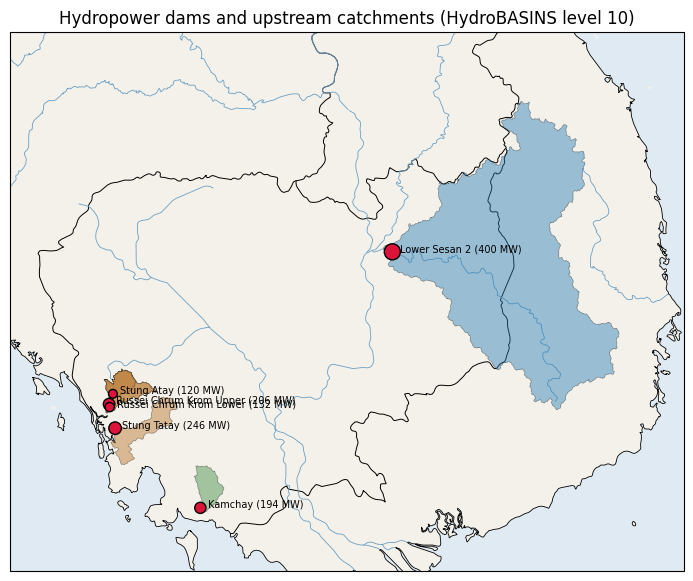

In [8]:
fig = plt.figure(figsize=(10, 7))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([BBOX[0], BBOX[2], BBOX[1], BBOX[3]])
ax.add_feature(cfeature.LAND, facecolor="#f4f1ea"); ax.add_feature(cfeature.OCEAN, facecolor="#dfeaf2")
ax.add_feature(cfeature.BORDERS, lw=0.7); ax.coastlines(lw=0.6)
ax.add_feature(cfeature.RIVERS, edgecolor="#6a9fc4", lw=0.6)
colors = {"Northeast": "#2a7fb8", "Cardamom": "#b8762a", "South": "#3d8c40"}
for c in catch.sort_values("area_km2", ascending=False).itertuples():
    ax.add_geometries([c.geometry], crs=ccrs.PlateCarree(), facecolor=colors[c.region],
                      edgecolor="k", lw=0.4, alpha=0.45)
ax.scatter(dams.lon, dams.lat, s=dams.mw / 3, c="crimson", edgecolor="k", zorder=5, transform=ccrs.PlateCarree())
for d in dams.itertuples():
    ax.text(d.lon + 0.08, d.lat, f"{d.dam} ({d.mw} MW)", fontsize=7, transform=ccrs.PlateCarree())
ax.set_title("Hydropower dams and upstream catchments (HydroBASINS level 10)")
plt.show()

**생각해 볼 것:** 하세산2 유역 중 캄보디아 안에 있는 부분은 얼마나 되나요? 유역 대부분이 베트남에 있다면, 하세산2의 물은 **베트남 고원의 강수와 베트남 쪽 상류 댐 운영**에 달려 있어요. 중국 란창강과는 상관이 없지만, 또 다른 국경을 넘는 물 문제예요.

## 2. 유역 범위로 CHIRPS 다시 받기
02 노트북의 CHIRPS는 캄보디아 사각형(102–108°E, 10–15°N)이라 베트남 고원이 빠져요. 하세산2 상류까지 포함하도록 영역을 넓혀 다시 받아요.

In [9]:
%%time
FN = "chirps_dams_monthly.nc"
if not os.path.exists(FN):
    ver, mb = iri_chirps(FN, BBOX)
    print(f"CHIRPS {ver}: {mb:.1f} MB")
pr_mm = open_iri(FN)
print("기간:", str(pr_mm.time.values[0])[:7], "→", str(pr_mm.time.values[-1])[:7],
      "| 격자:", pr_mm.lat.size, "x", pr_mm.lon.size)

CHIRPS v2p0: 39.8 MB
기간: 1981-01 → 2026-09 | 격자: 120 x 151
CPU times: user 1.28 s, sys: 269 ms, total: 1.55 s
Wall time: 3min 17s


In [10]:
def region_series(da, geom):
    # 다각형 안 격자들의 위도 가중 평균 시계열
    m = regionmask.Regions([geom]).mask(da)
    if int(m.notnull().sum()) == 0:                 # 다각형이 격자 하나보다 작을 때: 가장 가까운 격자
        c = geom.centroid
        return da.sel(lon=c.x, lat=c.y, method="nearest").to_series()
    return area_mean(da.where(m.notnull())).to_series()

countries = regionmask.defined_regions.natural_earth_v5_0_0.countries_50
khm_mask = countries.mask(pr_mm) == countries.map_keys("Cambodia")

series = {"Cambodia (national)": area_mean(pr_mm.where(khm_mask)).to_series()}
for c in catch.itertuples():
    series[c.dam] = region_series(pr_mm, c.geometry)
P = pd.DataFrame(series)

base = P.loc[BASE[0]:BASE[1]]
summary = pd.DataFrame({
    "연강수 (mm)": base.groupby(base.index.year).sum().mean(),
    "건기 1–4월 (mm)": base[base.index.month <= 4].groupby(base[base.index.month <= 4].index.year).sum().mean(),
})
summary.round(0)

,연강수 (mm),건기 1–4월 (mm)
Cambodia (national),1990.0,180.0
Lower Sesan 2,2265.0,153.0
Russei Chrum Krom Upper,3019.0,358.0
Russei Chrum Krom Lower,3019.0,358.0
Stung Tatay,3385.0,323.0
Stung Atay,2905.0,347.0
Kamchay,2114.0,257.0


**확인:** 카르다몸 산맥 유역은 국가 평균(약 2,000 mm)보다 훨씬 비가 많아야 해요(3주차 지도에서 4,000 mm 이상). 하세산2 유역은 그 중간쯤일 거예요. 숫자가 이와 맞는지 보세요.

## 3. 유역별 SPI: 2019·2020년은 몇 번째로 건조했나?
3주차와 같은 지표를 유역마다 계산해요. 순위는 1981년 이후 모든 해 중 **건조한 순서**(1 = 가장 건조)예요.

In [11]:
months, years = P.index.month.values, P.index.year.values
is_base = (years >= int(BASE[0])) & (years <= int(BASE[1]))
SPI = {w: pd.DataFrame({k: spi_1d(P[k].values, months, w, is_base) for k in P}, index=P.index) for w in (3, 6, 12)}

CHECKS = [("2018 우기\nSPI-6 Oct", 6, 10, 2018),
          ("2019 건기\nSPI-3 Apr", 3, 4, 2019),
          ("2019 1년\nSPI-12 Apr", 12, 4, 2019),
          ("2019 우기\nSPI-6 Oct", 6, 10, 2019),
          ("2020 1년\nSPI-12 Apr", 12, 4, 2020)]

def yearly(w, month, col):
    s = SPI[w][col]
    s = s[s.index.month == month]
    return pd.Series(s.values, index=s.index.year).dropna()

table, ranks = {}, {}
for col in P:
    table[col], ranks[col] = {}, {}
    for label, w, mon, yr in CHECKS:
        s = yearly(w, mon, col)
        if yr in s.index:
            rk = int(s.rank(method="min").loc[yr])
            table[col][label] = f"{s.loc[yr]:+.2f} ({rk}/{len(s)})"
            ranks[col][label] = rk
pd.DataFrame(table).T

,2018 우기\nSPI-6 Oct,2019 건기\nSPI-3 Apr,2019 1년\nSPI-12 Apr,2019 우기\nSPI-6 Oct,2020 1년\nSPI-12 Apr
Cambodia (national),-0.54 (13/45),-0.48 (17/46),-0.64 (14/45),-2.10 (2/45),-2.00 (3/45)
Lower Sesan 2,-0.45 (14/45),-0.69 (13/46),-0.49 (14/45),-2.47 (1/45),-2.17 (1/45)
Russei Chrum Krom Upper,-0.83 (9/45),-0.12 (23/46),-0.84 (10/45),-1.69 (6/45),-1.54 (5/45)
Russei Chrum Krom Lower,-0.83 (9/45),-0.12 (23/46),-0.84 (10/45),-1.69 (6/45),-1.54 (5/45)
Stung Tatay,-0.09 (16/45),-0.39 (19/46),-0.25 (15/45),-1.18 (7/45),-1.13 (8/45)
Stung Atay,-1.00 (9/45),-0.10 (22/46),-0.96 (10/45),-1.79 (5/45),-1.59 (4/45)
Kamchay,-0.35 (13/45),-0.89 (11/46),-0.51 (12/45),-0.85 (9/45),-0.91 (8/45)


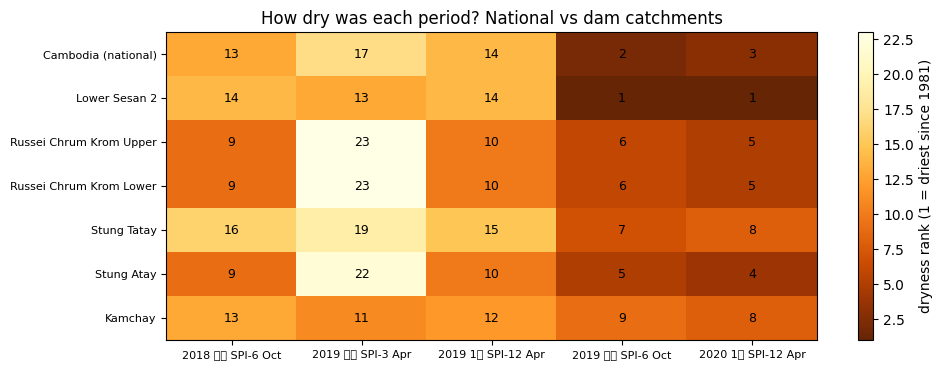

In [12]:
# 순위를 색으로: 진할수록 건조한 순위 (1 = 1981년 이후 가장 건조)
R = pd.DataFrame(ranks).T
fig, ax = plt.subplots(figsize=(10, 3.8))
im = ax.imshow(R.values, cmap="YlOrBr_r", vmin=1, vmax=23, aspect="auto")
for i in range(R.shape[0]):
    for j in range(R.shape[1]):
        ax.text(j, i, int(R.values[i, j]), ha="center", va="center", fontsize=9)
ax.set_xticks(range(R.shape[1])); ax.set_xticklabels([c.replace("\n", " ") for c in R.columns], fontsize=8)
ax.set_yticks(range(R.shape[0])); ax.set_yticklabels(R.index, fontsize=8)
plt.colorbar(im, ax=ax, label="dryness rank (1 = driest since 1981)")
ax.set_title("How dry was each period? National vs dam catchments")
plt.tight_layout(); plt.show()

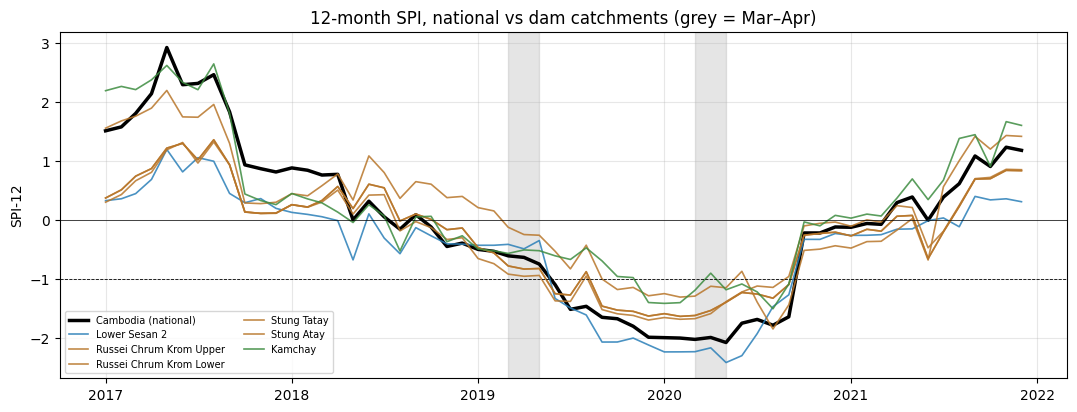

In [13]:
# SPI-12 시계열 2017–2021: 정전이 있었던 2019년 3–4월과 2020년 3–4월에 회색 표시
fig, ax = plt.subplots(figsize=(13, 4.5))
sub = SPI[12].loc["2017":"2021"]
for col in sub:
    if col == "Cambodia (national)":
        ax.plot(sub.index, sub[col], color="k", lw=2.5, label=col)
    else:
        reg = catch.set_index("dam").loc[col, "region"]
        ax.plot(sub.index, sub[col], color=colors[reg], lw=1.2, alpha=0.85, label=col)
for y in (2019, 2020):
    ax.axvspan(pd.Timestamp(y, 3, 1), pd.Timestamp(y, 4, 30), color="grey", alpha=0.2)
ax.axhline(-1, color="k", lw=0.6, ls="--"); ax.axhline(0, color="k", lw=0.5)
ax.set_ylabel("SPI-12"); ax.legend(fontsize=7, ncol=2, loc="lower left"); ax.grid(alpha=0.3)
ax.set_title("12-month SPI, national vs dam catchments (grey = Mar–Apr)")
plt.show()

**해석 질문**
1. 2019년 4월 SPI-12에서 국가 평균(14위 안팎)보다 **더 건조한 순위**를 보인 유역이 있나요? 어느 지역인가요?
2. 하세산2(북동부)와 카르다몸 댐들은 같은 시기에 같은 방향으로 움직이나요? 지역마다 다르다면, 댐이 여러 지역에 흩어져 있는 게 전력 시스템에 어떤 의미일까요? (힌트: 분산 투자)
3. 2020년 4월은 모든 유역에서 2019년보다 나빴나요?

## 4. 설비용량 가중 "수력 가뭄 지수"
유역마다 SPI가 다르면 전력 시스템 전체로는 어떨까요? 각 댐 유역의 4월 SPI-12에 **설비용량(MW)으로 가중치**를 주어 평균해요. 큰 댐 유역이 가물면 지수가 더 크게 내려가요.

$$\text{Hydro SPI}_y = \frac{\sum_d \text{MW}_d \times \text{SPI}_{d,y}}{\sum_d \text{MW}_d}$$

간단하지만 정책 담당자에게 "올해 수력 설비가 겪는 강수 부족"을 숫자 하나로 보여 줄 수 있어요. 실제 발전량은 저수지 크기와 운영에도 달려 있다는 점은 한계로 적어 두세요.

2016: 수력 가중 SPI-12 -1.50 (건조 순위 3/45) | 국가 평균 -2.10
2019: 수력 가중 SPI-12 -0.58 (건조 순위 13/45) | 국가 평균 -0.64
2020: 수력 가중 SPI-12 -1.57 (건조 순위 2/45) | 국가 평균 -2.00
2024: 수력 가중 SPI-12 -1.14 (건조 순위 6/45) | 국가 평균 -0.74


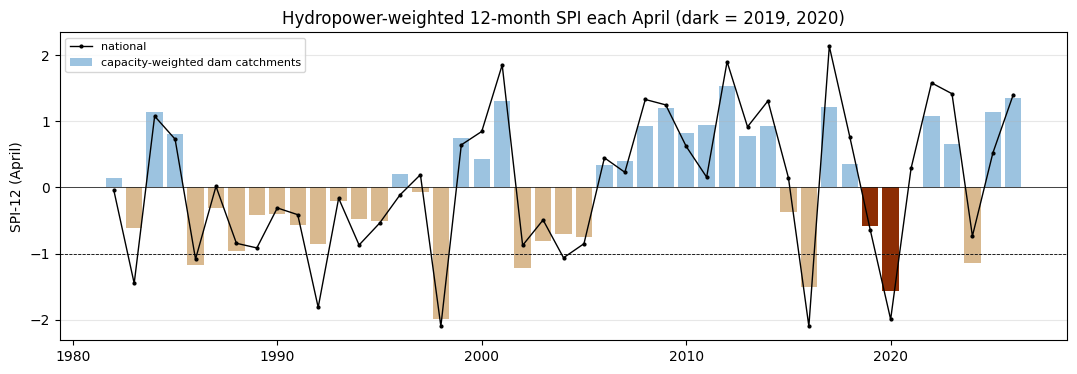

In [14]:
apr12 = pd.DataFrame({c.dam: yearly(12, 4, c.dam) for c in catch.itertuples()})
w = catch.set_index("dam").mw
hydro = ((apr12[w.index] * w).sum(axis=1, min_count=len(w)) / w.sum()).dropna()   # 빈 해(1981)는 0이 아니라 제외
national = yearly(12, 4, "Cambodia (national)")

rk = hydro.rank(method="min")
for y in (2016, 2019, 2020, 2024):
    if y in hydro.index:
        print(f"{y}: 수력 가중 SPI-12 {hydro.loc[y]:+.2f} (건조 순위 {int(rk.loc[y])}/{len(hydro)}) "
              f"| 국가 평균 {national.loc[y]:+.2f}")

fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(hydro.index, hydro.values, color=np.where(hydro.values < 0, "#d9b98f", "#9cc3e0"), width=0.8,
       label="capacity-weighted dam catchments")
for y in (2019, 2020):
    if y in hydro.index:
        ax.bar(y, hydro.loc[y], color="#8c2d04", width=0.8)
ax.plot(national.index, national.values, "k.-", lw=1, ms=4, label="national")
ax.axhline(-1, color="k", lw=0.6, ls="--"); ax.axhline(0, color="k", lw=0.5)
ax.set_ylabel("SPI-12 (April)"); ax.legend(fontsize=8); ax.grid(alpha=0.3, axis="y")
ax.set_title("Hydropower-weighted 12-month SPI each April (dark = 2019, 2020)")
plt.show()

**해석 질문**
1. 수력 가중 지수로 보면 2019년은 국가 평균보다 더 건조한가요, 덜 건조한가요?
2. 하세산2가 가동되기 전(2017년 이전)에도 같은 가중치를 쓰는 게 맞을까요? 연도별로 **그해 가동 중이던 댐만** 넣으려면 코드를 어떻게 바꿔야 할까요? (힌트: `dams.year`)

## 5. 정리
- [ ] 메모 채우기 → GitHub `notebooks/03_dam_catchments.ipynb`로 업로드
- [ ] README Progress 표에 4주차 한 줄, notebooks/README.md 목록에 03 추가
- [ ] `hydrobasins/` 폴더와 `.nc` 파일은 올리지 않기 (용량이 커요)

**메모: 2019년 정전의 위해·노출·취약성**

| 요소 | 2019년 캄보디아 | 근거 |
| --- | --- | --- |
| 위해 | 국가 평균 SPI-12 −0.64 (14위), 댐 유역 −0.25 ~ −0.96 (10–15위), 수력 가중 −0.58 (13위). 극단적이지 않음 | 03 노트북 3–4장 |
| 노출 | 전력의 약 절반이 수력 | Asia Times (2019) |
| 취약성 | 2018년 수요 15% 증가, 수입 비중 약 60%(2010) → 약 20%, 베트남 추가 판매 거절 | Asia Times (2019) |

**결론**: 2019년 정전은 평범한 수준의 강수 부족이 수요 급증과 약해진 수입 완충과 겹쳐 일어났다.
반면 2020년 건기에는 하세산2 유역이 1981년 이후 가장 건조했고(SPI-12 −2.17), 수력 가중 지수도 45년 중 2위였다.